In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datasets import load_dataset
import ast
import seaborn as sns
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [2]:
df_IND = df[df['job_country'] == 'India']

In [3]:
df_skills = df_IND.explode('job_skills')

In [6]:
df_skills_count = df_skills.groupby(['job_skills','job_title_short']).size()

df_skills_count = df_skills_count.reset_index(name='skill_count')

In [7]:
df_skills_count.sort_values(by='skill_count', ascending=False, inplace=True)

In [12]:
job_titles = df_skills_count['job_title_short'].unique().tolist()

In [15]:
job_titles = sorted(job_titles[:3])

['Data Analyst', 'Data Engineer', 'Data Scientist']

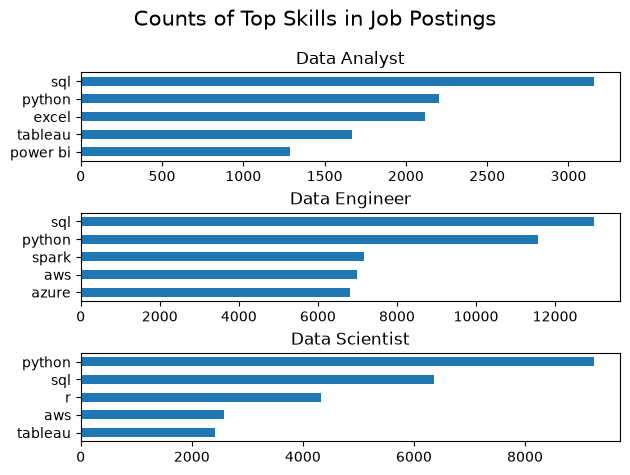

In [18]:
fig, ax = plt.subplots(len(job_titles), 1)

for i, job_title in enumerate(job_titles):

    df_plot = df_skills_count[df_skills_count['job_title_short'] == job_title].head(5)

    df_plot.plot(kind='barh' , x='job_skills', y='skill_count', ax=ax[i], title=job_title)

    ax[i].invert_yaxis()

    ax[i].set_ylabel('')

    ax[i].legend().set_visible(False)

fig.suptitle('Counts of Top Skills in Job Postings', fontsize=15)
plt.tight_layout(h_pad=0.5)
plt.show()

In [26]:
df_job_title_count = df_IND['job_title_short'].value_counts().reset_index(name='jobs_total')

In [31]:
df_skills_perc = pd.merge(df_skills_count, df_job_title_count, how='left', on='job_title_short')

df_skills_perc['skill_percent'] = (df_skills_perc['skill_count'] / df_skills_perc['jobs_total']) * 100

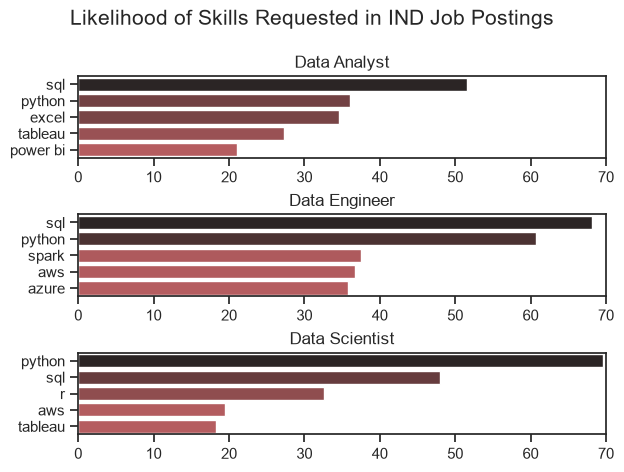

In [35]:
fig, ax = plt.subplots(len(job_titles), 1)
sns.set_theme(style='ticks')
for i, job_title in enumerate(job_titles):

    df_plot = df_skills_perc[df_skills_perc['job_title_short'] == job_title].head(5)

    sns.barplot(data=df_plot, x='skill_percent', y='job_skills', ax=ax[i], hue='skill_count', palette='dark:r_r')

    ax[i].set_title(job_title)

    ax[i].set_ylabel('')

    ax[i].set_xlabel('')

    ax[i].get_legend().remove()

    ax[i].set_xlim(0,70)

fig.suptitle('Likelihood of Skills Requested in IND Job Postings', fontsize=15)
plt.tight_layout(h_pad=0.5)
plt.show()